In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 5.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
import torch

In [3]:
from ultralytics import YOLO

In [4]:
print("cude availabe",torch.cuda.is_available() )

cude availabe False


In [5]:
model = YOLO("yolo11n.pt")

print("YOLO model Loaded")

YOLO model Loaded


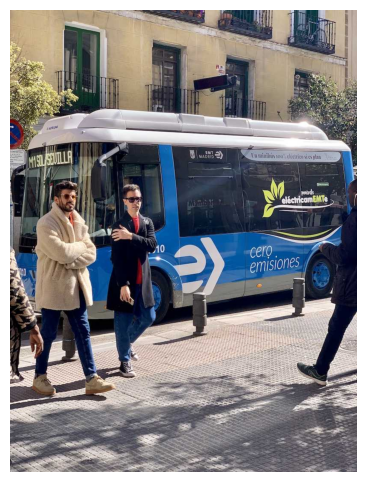

In [9]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

url = "https://ultralytics.com/images/bus.jpg"

response = requests.get(url)
response.raise_for_status


image = Image.open(BytesIO(response.content)).convert("RGB")

plt.figure(figsize=(10,6))
plt.imshow(image)
plt.axis("off")
plt.show()



In [11]:
results = model.predict(
    image,
    conf=0.25
)

print("Dectection Complete")


0: 640x480 4 persons, 1 bus, 222.7ms
Speed: 5.3ms preprocess, 222.7ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)
Dectection Complete


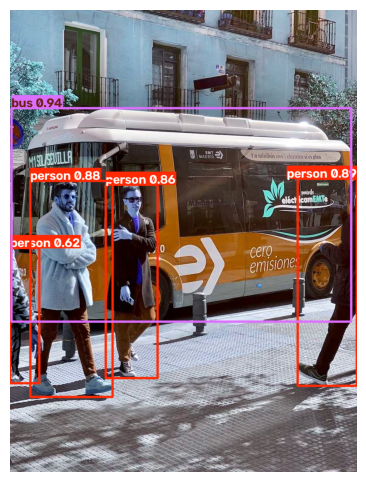

In [12]:
result = results[0]

annotated_image = result.plot()

plt.figure(figsize = (12,6))
plt.imshow(annotated_image)
plt.axis("off")
plt.show()

In [13]:
for box in result.boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = model.names[class_id]

    coordinates = box.xyxy[0].tolist()

    print("Object:", class_name)
    print("Confidence:", round(confidence, 3))
    print("Bounding Box:", coordinates)
    print("------------------")

Object: bus
Confidence: 0.94
Bounding Box: [3.8327178955078125, 229.36427307128906, 796.194580078125, 728.4122924804688]
------------------
Object: person
Confidence: 0.888
Bounding Box: [671.0172119140625, 394.83319091796875, 809.8097534179688, 878.7124633789062]
------------------
Object: person
Confidence: 0.878
Bounding Box: [47.404701232910156, 399.5651550292969, 239.3006591796875, 904.1949462890625]
------------------
Object: person
Confidence: 0.856
Bounding Box: [223.0589599609375, 408.68865966796875, 344.4676513671875, 860.435791015625]
------------------
Object: person
Confidence: 0.622
Bounding Box: [0.021725893020629883, 556.0684204101562, 68.88552856445312, 872.3591918945312]
------------------


In [15]:
result.save("yolo_detection.jpg")

print("Detection image saved")

Detection image saved
